In [33]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from typing import TypedDict , Annotated , Literal
from pydantic import BaseModel, Field
import os
import operator


In [34]:
from typing_extensions import TypedDict

class QuadState(TypedDict):
    a: float
    b: float
    c: float
    equation: str
    discriminant: float
    result: str

In [35]:
def calculate_discriminant(state: QuadState):
    return {
        "discriminant": state["b"]**2 - 4*state["a"]*state["c"]
    }

# def two_real_roots(state: QuadState):
#     return {
#         "result": "The equation has two real roots."
#     }

def two_real_roots(state: QuadState):
    root1=(-state["b"]+ state["discriminant"] ** 0.5)/(2*state["a"])
    root2 = (-state["b"]- state["discriminant"] ** 0.5)/(2*state["a"])
    result = f'The roots are {root1} and {root2}'
    return {'result': result}

def one_repeated_root(state: QuadState):
    return {
        "result": "The equation has one repeated root."
    }

def no_real_roots(state: QuadState):
    return {
        "result": "The equation has no real roots."
    }

def show_equation(state: QuadState):
    return {
        "equation": f"{state['a']}x² + {state['b']}x + {state['c']} = 0"
    }

def check_condition(state: QuadState)-> Literal["no_real_roots", "one_repeated_root", "two_real_roots"]:
    d = state["discriminant"]
    if d < 0:
        return "no_real_roots"
    elif d == 0:
        return "one_repeated_root"
    else:
        return "two_real_roots"


In [36]:
graph = StateGraph(QuadState)

# d=0 1 repeated root , d> 0 2 real root , d<0 no real roots

graph.add_node("calculate_discriminant",calculate_discriminant);
graph.add_node("no_real_roots",no_real_roots);
graph.add_node("one_repeated_root",one_repeated_root);
graph.add_node("two_real_roots",two_real_roots);
graph.add_node("show_equation",show_equation);


graph.add_edge(START, "show_equation")
graph.add_edge("show_equation", "calculate_discriminant")
# graph.add_edge("calculate_discriminant",END)

graph.add_conditional_edges("calculate_discriminant", check_condition)

graph.add_edge("no_real_roots",END)
graph.add_edge("one_repeated_root",END)
graph.add_edge("two_real_roots",END)



workflow = graph.compile()


In [40]:
initial_state = {
'a': 4,
'b': -0,
'c': -0
}
workflow.invoke(initial_state)

{'a': 4,
 'b': 0,
 'c': 0,
 'equation': '4x² + 0x + 0 = 0',
 'discriminant': 0,
 'result': 'The equation has one repeated root.'}

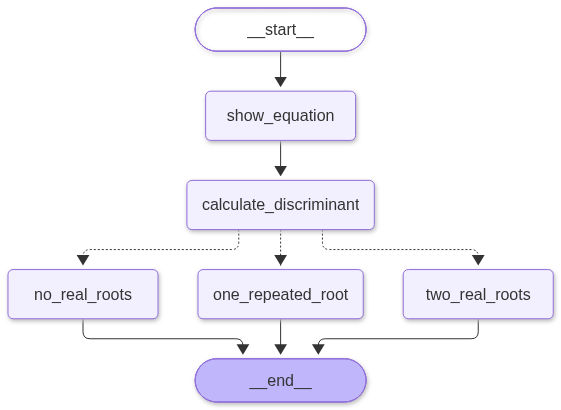

In [38]:
from IPython.display import display, Markdown , Image

Image(workflow.get_graph().draw_mermaid_png())